In [1]:
import os
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from glob import glob

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Importing Images**

In [24]:
# Input Images
BASE_INPUT = "/content/drive/MyDrive/Dataset Wildfire/Pre-Processed_Images/Jul_Dec_2024"

INPUT_DIRS = {
    "GLOBAL": os.path.join(BASE_INPUT, "agc_global/images"),
    "AUTO":   os.path.join(BASE_INPUT, "agc_per_image/images"),
    "FIXED":  os.path.join(BASE_INPUT, "agc_fixed/images"),
}

In [25]:
# Output Path
BASE_OUTPUT = "/content/drive/MyDrive/Dataset Wildfire/Post-Processed_Images/Jul_Dec_2024"

OUTPUT_DIRS = {
    "A": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_A/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_A/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_A/fixed"),
    },
    "B": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_B/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_B/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_B/fixed"),
    },
    "C": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_C/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_C/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_C/fixed"),
    }
}

for profile in OUTPUT_DIRS.values():
    for d in profile.values():
        os.makedirs(d, exist_ok=True)

## **Processing Functions**

In [26]:
# Lepton 3.5 Image Size
LEPTON_W = 160
LEPTON_H = 120

In [27]:
def split_into_4_regions(img):
    h, w, _ = img.shape
    h2, w2 = h // 2, w // 2

    return [
        img[0:h2,   0:w2],
        img[0:h2,   w2:w],
        img[h2:h,   0:w2],
        img[h2:h,   w2:w],
    ]

In [28]:
def resize_to_lepton(img):
    return cv2.resize(
        img,
        (LEPTON_W, LEPTON_H),
        interpolation=cv2.INTER_AREA
    )

In [29]:
def crop_valid_region(img, threshold=10):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Mask for Valid Regions
    mask = gray > threshold

    coords = np.column_stack(np.where(mask))
    if coords.size == 0:
        return img

    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0)

    return img[y0:y1+1, x0:x1+1]

In [30]:
def add_thermal_noise(img_rgb, sigma_celsius=2.5):
    img = img_rgb.astype(np.float32) / 255.0
    noise = np.random.normal(
        0.0,
        sigma_celsius / 100.0,
        size=img.shape
    )
    noisy = np.clip(img + noise, 0.0, 1.0)
    return (noisy * 255).astype(np.uint8)

In [31]:
def apply_optical_blur(img_rgb, sigma_px=1.0):
    k = int(2 * round(2 * sigma_px) + 1)
    return cv2.GaussianBlur(img_rgb, (k, k), sigmaX=sigma_px)

In [32]:
def generate_fpn(shape, strength=0.06):
    h, w, _ = shape
    return np.random.normal(0.0, strength, size=(h, w, 1))

def apply_fpn(img_rgb, fpn_map, factor=1.0):
    img = img_rgb.astype(np.float32) / 255.0
    img = img + factor * fpn_map
    img = np.clip(img, 0.0, 1.0)
    return (img * 255).astype(np.uint8)

## **Processing Images**

In [33]:
# Noise Pattern
FPN_MAP = generate_fpn((LEPTON_H, LEPTON_W, 3), strength=0.075)

In [34]:
def simulate_profile_A(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=1.0)
    img = apply_optical_blur(img, sigma_px=0.9)

    return np.clip(img, 0, 255).astype(np.uint8)

In [35]:
def simulate_profile_B(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=1.5)
    img = apply_optical_blur(img, sigma_px=1.0)
    img = apply_fpn(img, FPN_MAP, factor=0.8)

    return np.clip(img, 0, 255).astype(np.uint8)

In [36]:
def simulate_profile_C(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=3.5)
    img = apply_optical_blur(img, sigma_px=1.5)
    img = apply_fpn(img, FPN_MAP, factor=1.5)

    return np.clip(img, 0, 255).astype(np.uint8)

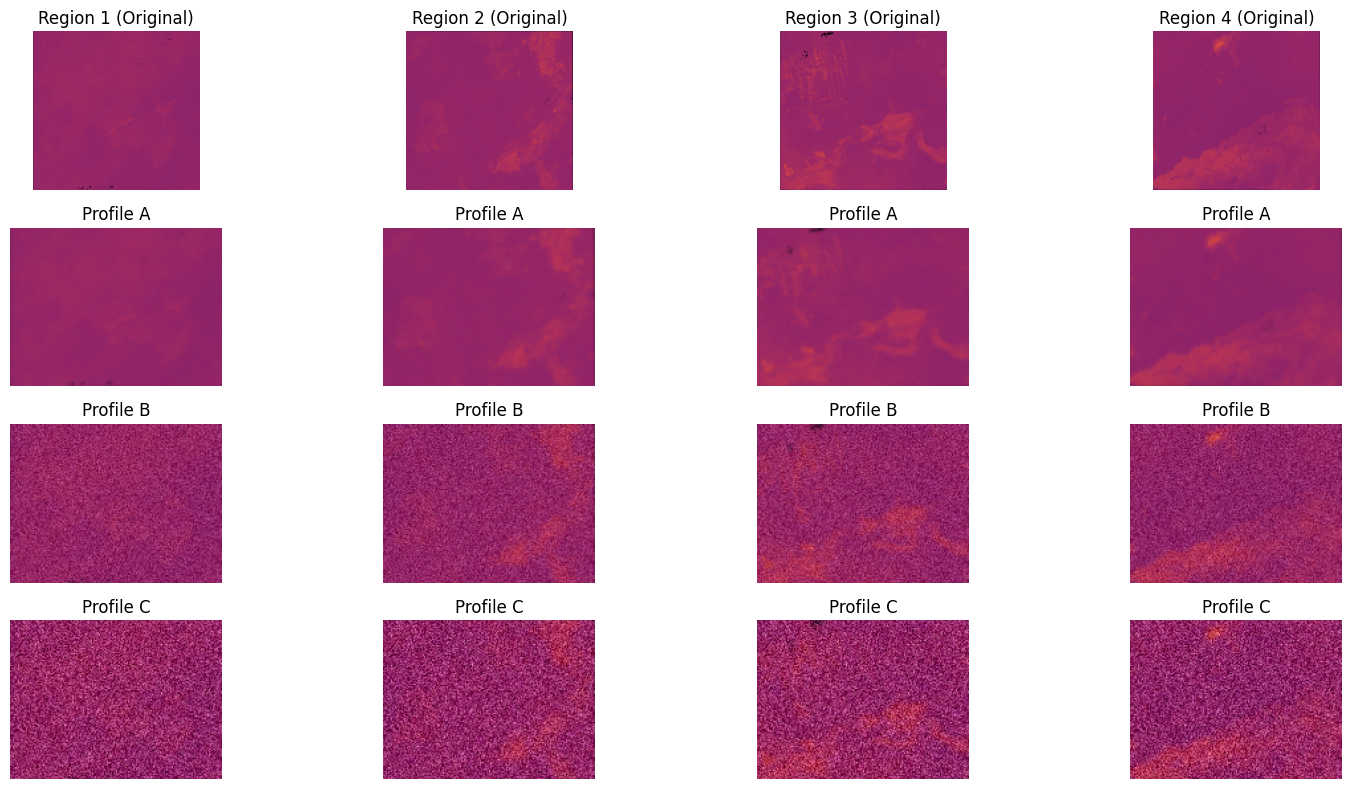

In [37]:
# Sample Image
sample_path = glob(os.path.join(INPUT_DIRS["FIXED"], "*.png"))[0]
img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)

img_clean = crop_valid_region(img)
regions = split_into_4_regions(img_clean)

plt.figure(figsize=(16, 8))

for i, region in enumerate(regions):
    outA = simulate_profile_A(region)
    outB = simulate_profile_B(region)
    outC = simulate_profile_C(region)

    plt.subplot(4, 4, i + 1)
    plt.imshow(region)
    plt.title(f"Region {i+1} (Original)")
    plt.axis("off")

    plt.subplot(4, 4, i + 5)
    plt.imshow(outA)
    plt.title(f"Profile A")
    plt.axis("off")

    plt.subplot(4, 4, i + 9)
    plt.imshow(outB)
    plt.title(f"Profile B")
    plt.axis("off")

    plt.subplot(4, 4, i + 13)
    plt.imshow(outC)
    plt.title(f"Profile C")
    plt.axis("off")

plt.tight_layout()
plt.show()

## **Saving Images**

In [38]:
for mode, in_dir in INPUT_DIRS.items():
    images = sorted(glob(os.path.join(in_dir, "*.png")))

    for img_path in tqdm(images, desc=f"Processing {mode}", leave=True):
        base = os.path.splitext(os.path.basename(img_path))[0]

        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            continue

        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Removing Black Areas
        img_clean = crop_valid_region(img)

        # Checking Size
        h, w, _ = img_clean.shape
        if h < 20 or w < 20:
            continue

        regions = split_into_4_regions(img_clean)

        for idx, region in enumerate(regions):
            # Profile A
            outA = simulate_profile_A(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["A"][mode],
                    f"{base}_r{idx}_A.png"
                ),
                cv2.cvtColor(outA, cv2.COLOR_RGB2BGR)
            )

            # Profile B
            outB = simulate_profile_B(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["B"][mode],
                    f"{base}_r{idx}_B.png"
                ),
                cv2.cvtColor(outB, cv2.COLOR_RGB2BGR)
            )

            # Profile C
            outC = simulate_profile_C(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["C"][mode],
                    f"{base}_r{idx}_C.png"
                ),
                cv2.cvtColor(outC, cv2.COLOR_RGB2BGR)
            )

Processing FIXED: 100%|██████████| 106/106 [00:57<00:00,  1.83it/s]
